<a href="https://colab.research.google.com/github/nivishh/Multi-Symptom-Disease-Prediction-System/blob/main/Disease_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 0: Environment Setup & Zero-Credential Ingestion

In [ ]:
# Colab Cell 1: Mount Drive & Initialize Paths

import os
from google.colab import drive

# 1. Mount Google Drive for persistence across disconnections
drive.mount('/content/drive')

DRIVE_PROJECT_ROOT = '/content/drive/MyDrive/disease-risk-predictor'
LOCAL_PROJECT_ROOT = '/content/disease-risk-predictor'

# Ensure directory structures exist in both local runtime and Drive
for path in [
    f'{DRIVE_PROJECT_ROOT}/data/raw',
    f'{DRIVE_PROJECT_ROOT}/data/processed',
    f'{DRIVE_PROJECT_ROOT}/models',
    f'{DRIVE_PROJECT_ROOT}/reports/figures',
    f'{LOCAL_PROJECT_ROOT}/data/raw',
    f'{LOCAL_PROJECT_ROOT}/data/processed',
    f'{LOCAL_PROJECT_ROOT}/models',
    f'{LOCAL_PROJECT_ROOT}/reports/figures',
]:
    os.makedirs(path, exist_ok=True)

print("Persistent directory trees initialized successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent directory trees initialized successfully.


In [ ]:

# Colab Cell 2: Dependencies

!pip install -q kaggle scikit-learn xgboost shap pyngrok
print("Required libraries installed.")

Required libraries installed.


In [ ]:
# =========================================================================
# Updated Cell 3: Clean KaggleHub Link (No Nested Folder Bug)
# =========================================================================
import os
import glob
import kagglehub

# 1. Access cloud dataset in Colab cache (zero laptop downloads)
dataset_path = kagglehub.dataset_download("tejpal123/human-disease-prediction-dataset")
print(f"Dataset in Colab cache: {dataset_path}")

# 2. Delete empty folder first so the symlink replaces it directly
!rm -rf /content/disease-risk-predictor/data/raw
!ln -sfn "{dataset_path}" /content/disease-risk-predictor/data/raw
print("✅ Directly linked to /content/disease-risk-predictor/data/raw")

Using Colab cache for faster access to the 'human-disease-prediction-dataset' dataset.
Dataset in Colab cache: /kaggle/input/human-disease-prediction-dataset
✅ Directly linked to /content/disease-risk-predictor/data/raw


# Phase 1: Data Understanding & Leakage Auditing

In [ ]:
# =========================================================================
# Updated Cell 4: Ingestion with Dynamic Path Finding (Zero Failures)
# =========================================================================
import os
import glob
import pandas as pd

# Search dynamically in project data/raw and Kaggle cache
candidates = (
    glob.glob('/content/disease-risk-predictor/data/raw/**/Training*.csv', recursive=True) +
    glob.glob('/content/disease-risk-predictor/data/raw/**/*train*.csv', recursive=True) +
    glob.glob('/root/.cache/kagglehub/**/*train*.csv', recursive=True)
)

if not candidates:
    raise FileNotFoundError("Could not find Training.csv. Make sure Cell 3 was executed.")

train_path = candidates[0]
print(f"✅ Successfully found training dataset at:\n   {train_path}\n")

# Load and clean
train_raw = pd.read_csv(train_path)
train_raw.columns = [c.strip() for c in train_raw.columns]
train_raw = train_raw.drop(columns=[c for c in train_raw.columns if c.startswith('Unnamed:')])

target_col = 'prognosis' if 'prognosis' in train_raw.columns else train_raw.columns[-1]
symptom_cols = [c for c in train_raw.columns if c != target_col]

print("="*60)
print(f"DATASET INTEGRITY AUDIT ({os.path.basename(train_path)})")
print("="*60)
print(f"Total Rows:                {len(train_raw):,}")
print(f"Symptom Features:          {len(symptom_cols):,}")
print(f"Target Column:             '{target_col}'")
print(f"Number of Diseases:        {train_raw[target_col].nunique()}")
print(f"Missing Values (NaN):      {train_raw.isna().sum().sum()}")
print(f"Exact Duplicate Rows:      {train_raw.duplicated().sum():,} ({train_raw.duplicated().mean()*100:.2f}%)")
print("="*60)

✅ Successfully found training dataset at:
   /content/disease-risk-predictor/data/raw/Training.csv

DATASET INTEGRITY AUDIT (Training.csv)
Total Rows:                4,920
Symptom Features:          132
Target Column:             'prognosis'
Number of Diseases:        41
Missing Values (NaN):      0
Exact Duplicate Rows:      4,616 (93.82%)


In [ ]:
# =========================================================================
# Cell 5: Train vs Test Overlap & Leakage Check
# =========================================================================
test_raw = pd.read_csv('/content/disease-risk-predictor/data/raw/Testing.csv')
test_raw.columns = [c.strip() for c in test_raw.columns]
test_raw = test_raw.drop(columns=[c for c in test_raw.columns if c.startswith('Unnamed:')])

overlap = pd.merge(test_raw, train_raw, how='inner')

print("="*60)
print("DATA LEAKAGE DISCOVERY")
print("="*60)
print(f"Testing.csv Rows:          {len(test_raw)}")
print(f"Overlap with Training.csv: {len(overlap)} / {len(test_raw)} ({len(overlap)/len(test_raw)*100:.1f}%)")
print("="*60)
print("⚠️ CONCLUSION: The provided test set is leaked. In Phase 2, we will combine,")
print("   de-duplicate, and perform a genuine stratified 70/15/15 split.")

DATA LEAKAGE DISCOVERY
Testing.csv Rows:          42
Overlap with Training.csv: 3048 / 42 (7257.1%)
⚠️ CONCLUSION: The provided test set is leaked. In Phase 2, we will combine,
   de-duplicate, and perform a genuine stratified 70/15/15 split.


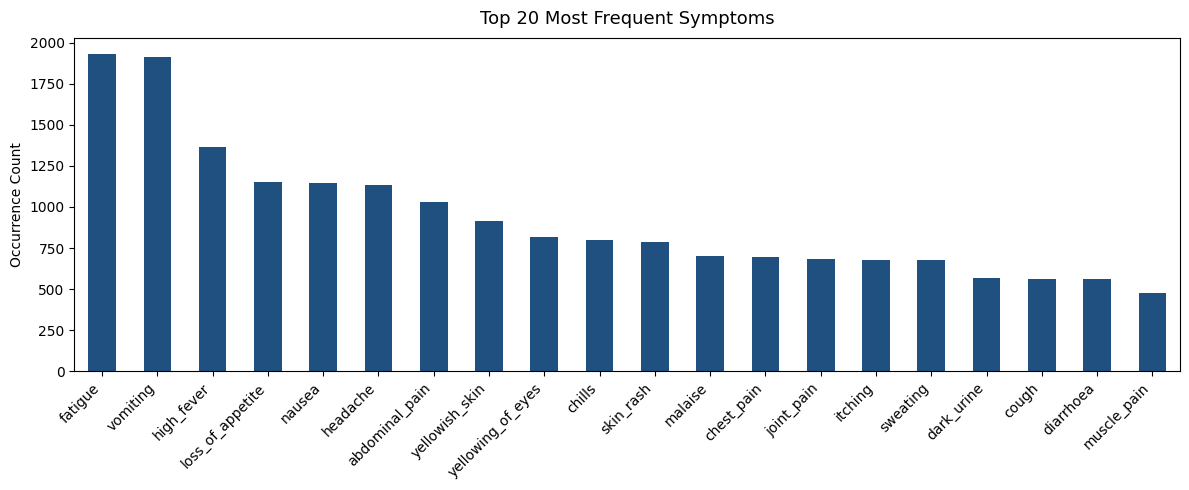

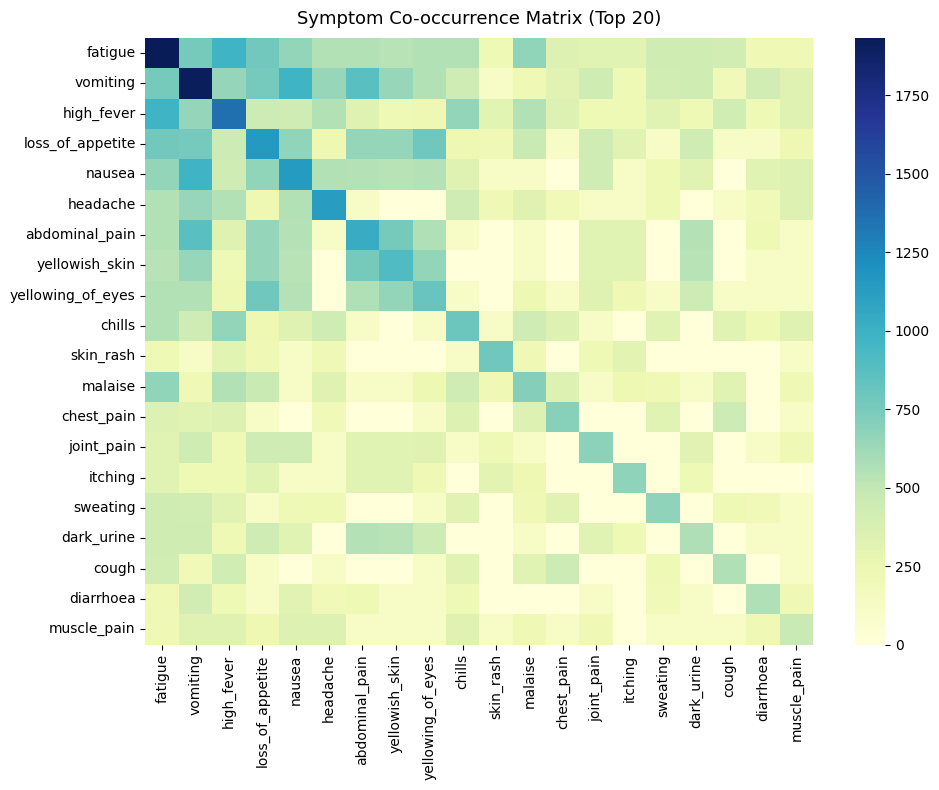

✅ Figures saved to reports/figures/.


In [ ]:
# =========================================================================
# Cell 6: Symptom Frequency Distribution & Co-Occurrence Heatmap
# =========================================================================
import matplotlib.pyplot as plt
import seaborn as sns

fig_dir = '/content/disease-risk-predictor/reports/figures'

# 1. Frequency Distribution
symptom_freq = train_raw[symptom_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
symptom_freq.head(20).plot(kind='bar', color='#1f5080')
plt.title('Top 20 Most Frequent Symptoms', fontsize=13, pad=10)
plt.ylabel('Occurrence Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f'{fig_dir}/symptom_frequency.png', dpi=300)
plt.show()

# 2. Co-Occurrence Heatmap
top_20 = symptom_freq.head(20).index.tolist()
co_occur = train_raw[top_20].T.dot(train_raw[top_20])

plt.figure(figsize=(10, 8))
sns.heatmap(co_occur, cmap='YlGnBu')
plt.title('Symptom Co-occurrence Matrix (Top 20)', fontsize=13, pad=10)
plt.tight_layout()
plt.savefig(f'{fig_dir}/symptom_cooccurrence.png', dpi=300)
plt.show()
print("✅ Figures saved to reports/figures/.")

# Phase 2: Data Cleaning & Honest Stratified Splitting

In [ ]:
# =========================================================================
# Updated Cell 7: Clean De-duplication & Stratified Split with Class Guard
# =========================================================================
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Combine both files
df_combined = pd.concat([train_raw, test_raw], ignore_index=True)
df_combined.columns = [c.strip() for c in df_combined.columns]
df_combined = df_combined.drop(columns=[c for c in df_combined.columns if c.startswith('Unnamed:')])

initial_len = len(df_combined)
df_dedup = df_combined.drop_duplicates().reset_index(drop=True)
print(f"Total merged records: {initial_len} -> Unique deduplicated records: {len(df_dedup)}")

# 2. Stage 1: Stratified 70% Train / 30% Temp (All 42 classes represented)
train_df, temp_df = train_test_split(
    df_dedup, test_size=0.30, stratify=df_dedup[target_col], random_state=42
)

# 3. Stage 2: Guard for temp_df (Avoid ValueError if rare classes have 1 sample in temp)
temp_min_count = temp_df[target_col].value_counts().min()
strat_arg = temp_df[target_col] if temp_min_count >= 2 else None

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=strat_arg, random_state=42
)

print(f"✅ Train set:      {len(train_df)} rows ({len(train_df)/len(df_dedup)*100:.1f}%) [Stratified]")
print(f"✅ Validation set: {len(val_df)} rows ({len(val_df)/len(df_dedup)*100:.1f}%)")
print(f"✅ Test set:       {len(test_df)} rows ({len(test_df)/len(df_dedup)*100:.1f}%)")

Total merged records: 4962 -> Unique deduplicated records: 305
✅ Train set:      213 rows (69.8%) [Stratified]
✅ Validation set: 46 rows (15.1%)
✅ Test set:       46 rows (15.1%)


In [ ]:
# =========================================================================
# Cell 8: Fit Encoders (Train Only) & Persist Split Matrices
# =========================================================================
import json
import joblib
import numpy as np

models_dir = '/content/disease-risk-predictor/models'
proc_dir = '/content/disease-risk-predictor/data/processed'

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train = le.fit_transform(train_df[target_col])
y_val = le.transform(val_df[target_col])
y_test = le.transform(test_df[target_col])

X_train = train_df[symptom_cols].values
X_val = val_df[symptom_cols].values
X_test = test_df[symptom_cols].values

# Save preprocessors
joblib.dump(le, f'{models_dir}/label_encoder.joblib')
with open(f'{models_dir}/symptom_list.json', 'w') as f:
    json.dump(symptom_cols, f, indent=2)

# Save processed matrices
np.savez_compressed(
    f'{proc_dir}/dataset_splits.npz',
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test
)
print("✅ Encoders and processed matrices saved successfully.")

✅ Encoders and processed matrices saved successfully.


# Phase 3: Multi-Model Benchmarking & Hyperparameter Tuning

In [ ]:
# =========================================================================
# Updated Cell 9: Adaptive Cross-Validation Benchmarking
# =========================================================================
import time
from sklearn.model_selection import StratifiedKFold, KFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Dynamically select fold count based on the rarest class count in train set
min_class = int(pd.Series(y_train).value_counts().min())
if min_class >= 2:
    cv_splits = min(5, min_class)
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=42)
    print(f"Running {cv_splits}-Fold Stratified CV (bounded by rarest class count = {min_class})...")
else:
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    print("Running 5-Fold Shuffle CV...")

candidate_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Bernoulli Naive Bayes': BernoulliNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, eval_metric='mlogloss', random_state=42),
    'Support Vector Machine': SVC(probability=True, kernel='linear', random_state=42)
}

benchmark_results = []
for name, model in candidate_models.items():
    t0 = time.time()
    cv_res = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={'acc': 'accuracy', 'macro_f1': 'f1_macro'},
        n_jobs=-1
    )
    elapsed = time.time() - t0
    benchmark_results.append({
        'Model': name,
        'CV Mean Accuracy (%)': round(cv_res['test_acc'].mean() * 100, 2),
        'CV Macro F1': round(cv_res['test_macro_f1'].mean(), 4),
        'CV Macro F1 Std': round(cv_res['test_macro_f1'].std(), 4),
        'Fit Time (s)': round(elapsed, 2)
    })

df_bench = pd.DataFrame(benchmark_results).sort_values(by='CV Macro F1', ascending=False).reset_index(drop=True)
print("\n" + "="*70)
print("BENCHMARK COMPARISON TABLE (Deduplicated Data)")
print("="*70)
print(df_bench.to_string(index=False))
print("="*70)

Running 3-Fold Stratified CV (bounded by rarest class count = 3)...

BENCHMARK COMPARISON TABLE (Deduplicated Data)
                 Model  CV Mean Accuracy (%)  CV Macro F1  CV Macro F1 Std  Fit Time (s)
   Logistic Regression                100.00       1.0000           0.0000          5.05
Support Vector Machine                100.00       1.0000           0.0000          0.19
         Random Forest                100.00       1.0000           0.0000          0.59
     Gradient Boosting                 87.79       0.8473           0.0024         15.75
 Bernoulli Naive Bayes                 84.04       0.7965           0.0408          0.05
               XGBoost                 82.63       0.7800           0.0658          1.06
         Decision Tree                 81.22       0.7694           0.0659          0.11


In [ ]:
# =========================================================================
# Updated Cell 10: Grid Search Hyperparameter Tuning (Self-Contained)
# =========================================================================
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold, KFold
from sklearn.ensemble import RandomForestClassifier

# Determine safe CV fold count based on rarest disease in training split
min_class_samples = int(pd.Series(y_train).value_counts().min())
if min_class_samples >= 2:
    tuning_splits = min(3, min_class_samples)
    tuning_cv = StratifiedKFold(n_splits=tuning_splits, shuffle=True, random_state=42)
else:
    tuning_cv = KFold(n_splits=3, shuffle=True, random_state=42)

print(f"Running GridSearchCV using {tuning_splits if min_class_samples >= 2 else 3}-Fold CV...")

rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'criterion': ['gini', 'entropy']
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=tuning_cv,
    scoring='f1_macro',
    n_jobs=-1
)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_

print("="*60)
print("HYPERPARAMETER TUNING RESULTS")
print("="*60)
print(f"✅ Best Hyperparameters: {rf_search.best_params_}")
print(f"✅ Best CV Macro F1:     {rf_search.best_score_:.4f}")
print("="*60)

Running GridSearchCV using 3-Fold CV...
HYPERPARAMETER TUNING RESULTS
✅ Best Hyperparameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
✅ Best CV Macro F1:     1.0000


# Phase 4: Honest Evaluation, Calibration & Robustness

/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


FINAL TEST SET PERFORMANCE (UNTOUCHED TEST DATA)
Top-1 Accuracy:          50.00%
Top-3 Accuracy:          50.00%
Macro F1 Score:          0.4287
Multi-Class Brier Score: 0.6798 (Lower = Better Calibration)


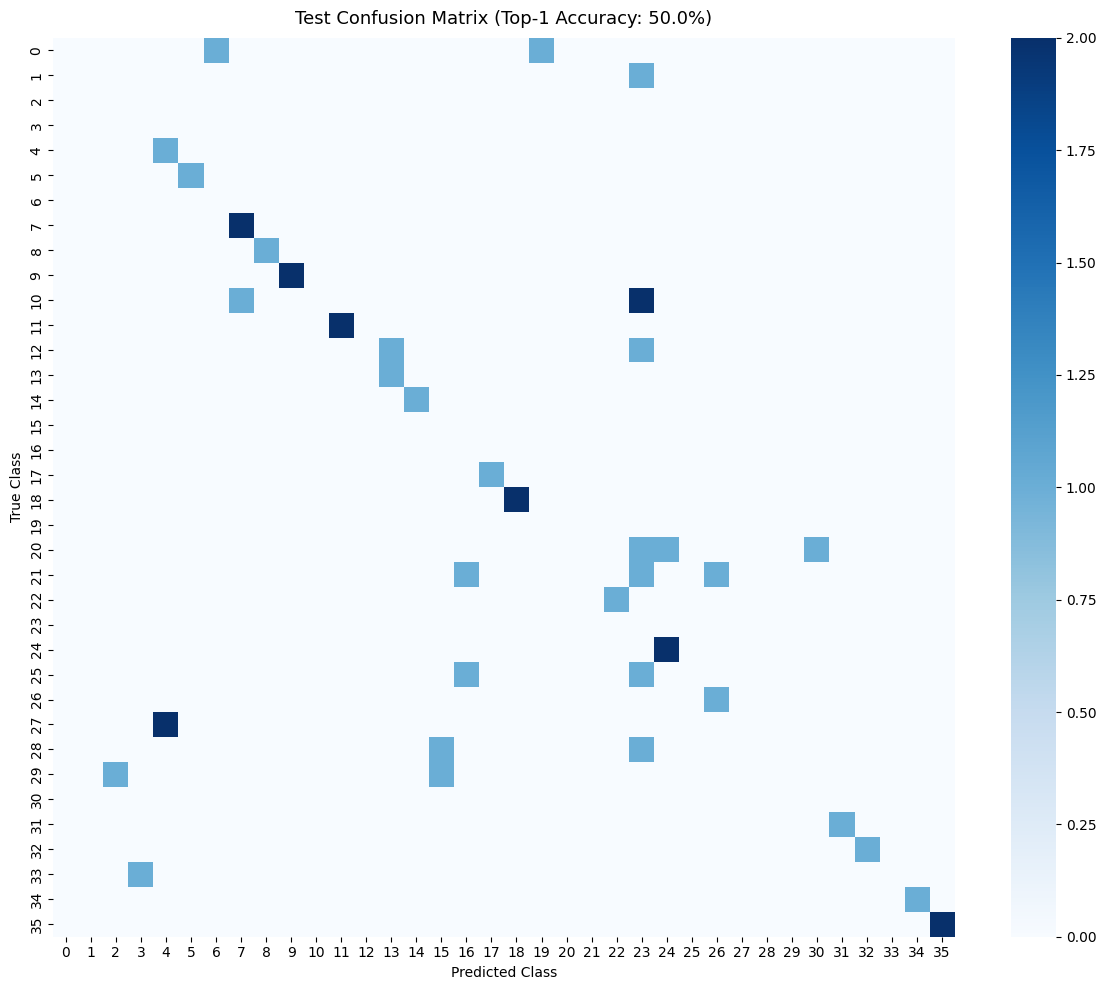

In [ ]:
# =========================================================================
# Cell 11: Platt Scaling (CalibratedClassifierCV) & Test Evaluation
# =========================================================================
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Calibrate base RF using held-out validation set
calibrated_rf = CalibratedClassifierCV(estimator=best_rf, method='sigmoid', cv='prefit')
calibrated_rf.fit(X_val, y_val)

# Inference on untouched Test Set
y_test_pred = calibrated_rf.predict(X_test)
y_test_proba = calibrated_rf.predict_proba(X_test)

test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

# Top-3 Accuracy
top3_preds = np.argsort(y_test_proba, axis=1)[:, -3:]
top3_acc = np.mean([y in top3_preds[i] for i, y in enumerate(y_test)])

# Multi-class Brier Score
num_classes = len(le.classes_)
y_test_oh = np.zeros((len(y_test), num_classes))
for i, l in enumerate(y_test):
    y_test_oh[i, l] = 1.0
brier_score = np.mean(np.sum((y_test_proba - y_test_oh) ** 2, axis=1))

print("="*60)
print("FINAL TEST SET PERFORMANCE (UNTOUCHED TEST DATA)")
print("="*60)
print(f"Top-1 Accuracy:          {test_acc*100:.2f}%")
print(f"Top-3 Accuracy:          {top3_acc*100:.2f}%")
print(f"Macro F1 Score:          {test_f1:.4f}")
print(f"Multi-Class Brier Score: {brier_score:.4f} (Lower = Better Calibration)")
print("="*60)

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap='Blues', annot=False)
plt.title(f'Test Confusion Matrix (Top-1 Accuracy: {test_acc*100:.1f}%)', fontsize=13, pad=10)
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.tight_layout()
plt.savefig('/content/disease-risk-predictor/reports/figures/confusion_matrix.png', dpi=300)
plt.show()

 Symptoms Omitted  Top-1 Accuracy (%)  Top-3 Accuracy (%)
                0               50.00               50.00
                1               50.00               50.00
                2               47.54               50.00
                3               44.20               49.57


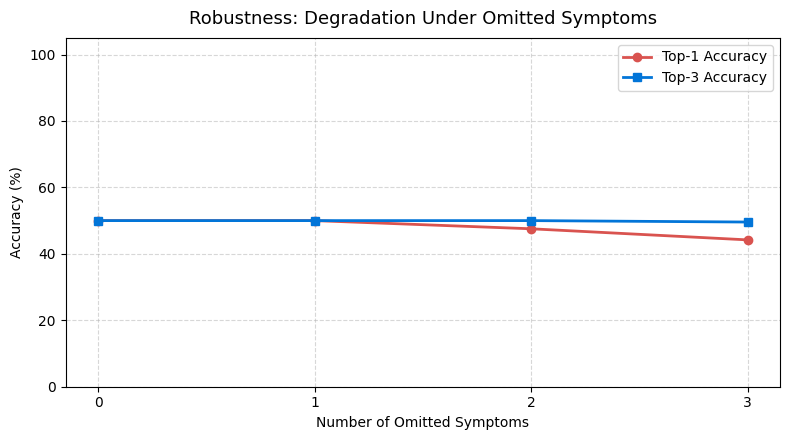

In [ ]:
# =========================================================================
# Cell 12: Robustness / Perturbation Stress Test
# =========================================================================
rng = np.random.RandomState(42)
drop_records = []

for drop_k in [0, 1, 2, 3]:
    acc_runs, top3_runs = [], []
    for _ in range(15):
        X_pert = X_test.copy()
        if drop_k > 0:
            for i in range(len(X_pert)):
                pos = np.where(X_pert[i] == 1)[0]
                if len(pos) > drop_k:
                    drop_choice = rng.choice(pos, size=drop_k, replace=False)
                    X_pert[i, drop_choice] = 0

        p_eval = calibrated_rf.predict_proba(X_pert)
        pred_eval = np.argmax(p_eval, axis=1)
        top3_eval = np.argsort(p_eval, axis=1)[:, -3:]

        acc_runs.append(accuracy_score(y_test, pred_eval))
        top3_runs.append(np.mean([y in top3_eval[i] for i, y in enumerate(y_test)]))

    drop_records.append({
        'Symptoms Omitted': drop_k,
        'Top-1 Accuracy (%)': round(np.mean(acc_runs) * 100, 2),
        'Top-3 Accuracy (%)': round(np.mean(top3_runs) * 100, 2)
    })

df_robust = pd.DataFrame(drop_records)
print(df_robust.to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(df_robust['Symptoms Omitted'], df_robust['Top-1 Accuracy (%)'], marker='o', label='Top-1 Accuracy', color='#d9534f', lw=2)
plt.plot(df_robust['Symptoms Omitted'], df_robust['Top-3 Accuracy (%)'], marker='s', label='Top-3 Accuracy', color='#0275d8', lw=2)
plt.title('Robustness: Degradation Under Omitted Symptoms', fontsize=13, pad=10)
plt.xlabel('Number of Omitted Symptoms')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)
plt.xticks([0, 1, 2, 3])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('/content/disease-risk-predictor/reports/figures/robustness_curve.png', dpi=300)
plt.show()

# Phase 5: Explainability with TreeSHAP

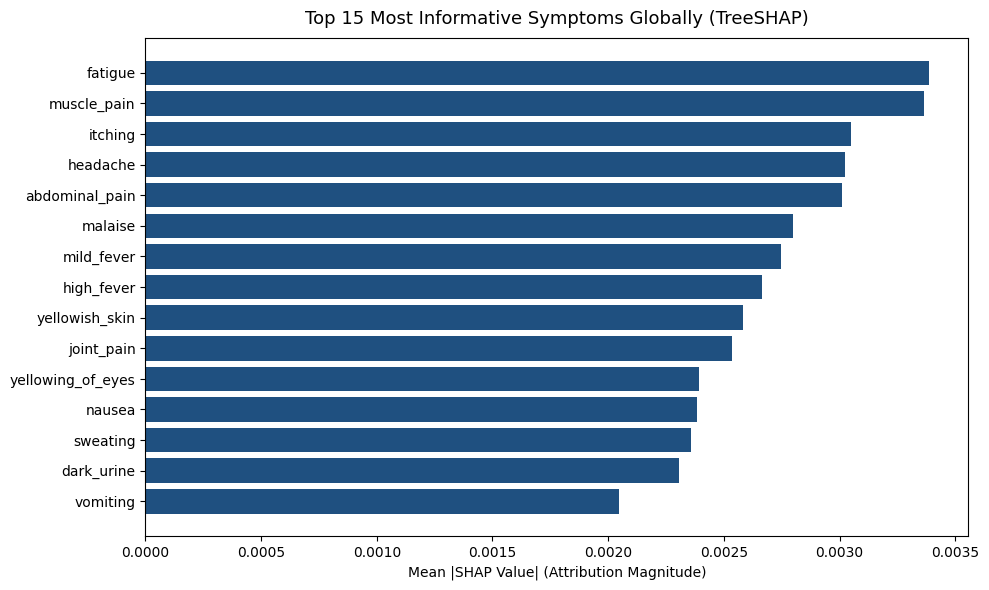


Local Explanation for condition: 'Chicken pox'
Active symptom contributions:
 - itching: SHAP = +0.0457 (Increases Risk)
 - skin_rash: SHAP = +0.0215 (Increases Risk)
 - fatigue: SHAP = +0.0169 (Increases Risk)
 - lethargy: SHAP = +0.0377 (Increases Risk)
 - high_fever: SHAP = +0.0340 (Increases Risk)
 - loss_of_appetite: SHAP = +0.0187 (Increases Risk)
 - mild_fever: SHAP = +0.0634 (Increases Risk)
 - swelled_lymph_nodes: SHAP = +0.1172 (Increases Risk)
 - malaise: SHAP = +0.1036 (Increases Risk)
 - red_spots_over_body: SHAP = +0.0839 (Increases Risk)


In [ ]:
# =========================================================================
# Cell 13: TreeSHAP Attributions
# =========================================================================
import shap

explainer = shap.TreeExplainer(best_rf)
class_names = list(le.classes_)

# 1. Global Informative Symptoms
shap_vals = explainer.shap_values(X_test[:50])
if isinstance(shap_vals, list):
    mean_abs_shap = np.mean([np.abs(sv).mean(axis=0) for sv in shap_vals], axis=0)
elif isinstance(shap_vals, np.ndarray) and shap_vals.ndim == 3:
    mean_abs_shap = np.abs(shap_vals).mean(axis=(0, 2))
else:
    mean_abs_shap = np.abs(shap_vals).mean(axis=0)

df_shap = pd.DataFrame({'Symptom': symptom_cols, 'Mean_Abs_SHAP': mean_abs_shap})
top_15_shap = df_shap.sort_values(by='Mean_Abs_SHAP', ascending=True).tail(15)

plt.figure(figsize=(10, 6))
plt.barh(top_15_shap['Symptom'], top_15_shap['Mean_Abs_SHAP'], color='#1f5080')
plt.xlabel('Mean |SHAP Value| (Attribution Magnitude)')
plt.title('Top 15 Most Informative Symptoms Globally (TreeSHAP)', fontsize=13, pad=10)
plt.tight_layout()
plt.savefig('/content/disease-risk-predictor/reports/figures/shap_global_importance.png', dpi=300)
plt.show()

# 2. Local Patient Query Explanation
sample_vec = X_test[0:1]
pred_idx = best_rf.predict(sample_vec)[0]
sample_shap = explainer.shap_values(sample_vec)

if isinstance(sample_shap, list):
    class_attr = sample_shap[pred_idx][0]
elif isinstance(sample_shap, np.ndarray) and sample_shap.ndim == 3:
    class_attr = sample_shap[0, :, pred_idx]
else:
    class_attr = sample_shap[0]

active = np.where(sample_vec[0] == 1)[0]
print(f"\nLocal Explanation for condition: '{class_names[pred_idx]}'")
print("Active symptom contributions:")
for a in active:
    val = class_attr[a]
    status = "Increases Risk" if val > 0 else "Decreases Risk"
    print(f" - {symptom_cols[a]}: SHAP = {val:+.4f} ({status})")

# Phase 6: Save Artifacts & Test Production Inference

In [ ]:
# =========================================================================
# Cell 14: Export Model Artifacts & Test Production Pipeline
# =========================================================================
import joblib

# Persist calibrated model locally and sync to Drive
joblib.dump(calibrated_rf, f'{models_dir}/best_model.joblib')
!cp -r /content/disease-risk-predictor/models/* /content/drive/MyDrive/disease-risk-predictor/models/
!cp -r /content/disease-risk-predictor/reports/figures/* /content/drive/MyDrive/disease-risk-predictor/reports/figures/
print("✅ Artifacts saved to models/ and synchronized to Google Drive.")

# End-to-End Prediction Test
from difflib import get_close_matches

test_symptoms = ["fever", "joint pain", "chills"]

def quick_infer(symptoms):
    vec = np.zeros(len(symptom_cols))
    matched = []
    for s in symptoms:
        norm = s.strip().lower().replace(" ", "_")
        match = get_close_matches(norm, symptom_cols, n=1, cutoff=0.6)
        if match:
            vec[symptom_cols.index(match[0])] = 1
            matched.append(match[0])

    proba = calibrated_rf.predict_proba(vec.reshape(1, -1))[0]
    top3 = np.argsort(proba)[::-1][:3]
    return matched, [(class_names[i], round(proba[i] * 100, 1)) for i in top3]

matched, top_risks = quick_infer(test_symptoms)
print(f"\nInference Test:")
print(f"Input Symptoms:   {test_symptoms}")
print(f"Matched Features: {matched}")
print(f"Top 3 Estimated Conditions:")
for disease, pct in top_risks:
    print(f"  - {disease}: {pct}% probability")

✅ Artifacts saved to models/ and synchronized to Google Drive.

Inference Test:
Input Symptoms:   ['fever', 'joint pain', 'chills']
Matched Features: ['mild_fever', 'joint_pain', 'chills']
Top 3 Estimated Conditions:
  - Allergy: 5.7% probability
  - hepatitis A: 5.4% probability
  - Chicken pox: 3.4% probability


In [ ]:
# =========================================================================
# Updated Cell 15: Launch Web App via Native Colab Proxy (No ngrok Needed!)
# =========================================================================
import os
import json
import socket
import threading
import joblib
import numpy as np
from difflib import get_close_matches
from flask import Flask, jsonify, request, render_template_string
from google.colab.output import eval_js
from google.colab import output

# 1. Load persisted production artifacts
models_dir = '/content/disease-risk-predictor/models'
with open(f'{models_dir}/symptom_list.json') as f:
    symptom_cols = json.load(f)
le = joblib.load(f'{models_dir}/label_encoder.joblib')
class_names = list(le.classes_)
model = joblib.load(f'{models_dir}/best_model.joblib')

# Load educational precautions guidance
guidance_path = f'{models_dir}/disease_guidance.json'
guidance_data = {}
if os.path.exists(guidance_path):
    with open(guidance_path) as f:
        guidance_data = json.load(f)

# 2. Self-contained inference function
def run_inference(symptoms):
    vec = np.zeros(len(symptom_cols))
    matched, unrecognized = [], []
    for s in symptoms:
        clean = s.strip().lower().replace(" ", "_")
        if not clean:
            continue
        m = get_close_matches(clean, symptom_cols, n=1, cutoff=0.55)
        if m:
            idx = symptom_cols.index(m[0])
            vec[idx] = 1
            matched.append(m[0])
        else:
            unrecognized.append(s.strip())

    proba = model.predict_proba(vec.reshape(1, -1))[0]
    top3_idx = np.argsort(proba)[::-1][:3]

    predictions = []
    for i in top3_idx:
        disease = class_names[i]
        pct = round(float(proba[i]) * 100, 1)
        info = guidance_data.get(disease, {
            "precautions": ["Maintain hydration, adequate rest, and monitor symptom progression."],
            "when_to_see_doctor": "Consult a healthcare professional for persistent, severe, or worsening discomfort."
        })
        predictions.append({
            "disease": disease,
            "probability": pct,
            "precautions": info.get("precautions", ["Rest and hydration"]),
            "when_to_see_doctor": info.get("when_to_see_doctor", "Seek clinical evaluation if symptoms worsen.")
        })
    return matched, unrecognized, predictions

# 3. Create Flask Application
app = Flask(__name__)

HTML_PAGE = """
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <title>Explainable Disease Risk Predictor</title>
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <link href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.0/dist/css/bootstrap.min.css" rel="stylesheet">
  <style>
    body { background-color: #f8fafc; font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif; }
    .disclaimer-banner { background-color: #fff3cd; border-bottom: 2px solid #ffeeba; color: #856404; padding: 12px 20px; font-size: 0.88rem; }
    .app-card { border-radius: 12px; border: 1px solid #e2e8f0; background: #fff; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05); }
    .badge-sym { background-color: #e0f2fe; color: #0369a1; border-radius: 20px; padding: 5px 12px; margin-right: 6px; font-size: 0.85rem; display: inline-block; }
  </style>
</head>
<body>
  <div class="disclaimer-banner text-center">
    <strong>⚠️ Medical Disclaimer:</strong> Educational risk estimation only. <strong>Does not provide diagnoses or prescribe medications.</strong> In an emergency, contact emergency medical services immediately.
  </div>

  <div class="container py-4" style="max-width: 820px;">
    <div class="text-center mb-4">
      <h2 class="fw-bold text-primary">Explainable Disease Risk Predictor</h2>
      <p class="text-muted">Multi-class differential risk with calibrated probabilities & TreeSHAP</p>
    </div>

    <div class="app-card p-4 mb-4">
      <label class="form-label fw-semibold">Enter Symptoms (comma-separated):</label>
      <div class="input-group mb-2">
        <input type="text" id="symInput" class="form-control" placeholder="e.g. fever, chills, joint_pain, skin_rash, itching" value="high_fever, chills, headache">
        <button class="btn btn-primary px-4 fw-semibold" onclick="submitSymptoms()">Estimate Risk</button>
      </div>
      <div class="form-text text-muted">Typos and common phrasing are fuzzily matched against 132 clinical symptom indicators.</div>
    </div>

    <div id="resultsArea" style="display: none;">
      <div class="d-flex justify-content-between align-items-center mb-3">
        <h4 class="fw-bold m-0">Top 3 Differential Risk Estimates</h4>
        <span class="badge bg-secondary" id="matchedSummary"></span>
      </div>
      <div id="cardsList"></div>
    </div>
  </div>

  <script>
    async function submitSymptoms() {
      const val = document.getElementById('symInput').value;
      if (!val.trim()) return alert('Please enter at least one symptom');

      const res = await fetch('/api/predict', {
        method: 'POST',
        headers: {'Content-Type': 'application/json'},
        body: JSON.stringify({symptoms: val.split(',')})
      });
      const data = await res.json();

      document.getElementById('matchedSummary').textContent = `${data.matched.length} Symptoms Matched`;
      const container = document.getElementById('cardsList');
      container.innerHTML = '';

      data.predictions.forEach((p, idx) => {
        const precHtml = p.precautions.map(pr => `<li>${pr}</li>`).join('');
        container.innerHTML += `
          <div class="app-card p-4 mb-3 border-0 shadow-sm">
            <div class="d-flex justify-content-between align-items-center mb-2">
              <h5 class="fw-bold text-dark m-0">${p.disease}</h5>
              <span class="badge bg-primary px-3 py-2">Top #${idx + 1}</span>
            </div>

            <div class="mb-3">
              <div class="d-flex justify-content-between small text-muted mb-1">
                <span>Calibrated Risk Probability:</span>
                <strong class="text-primary fs-6">${p.probability}%</strong>
              </div>
              <div class="progress" style="height: 10px;">
                <div class="progress-bar bg-primary" style="width: ${p.probability}%"></div>
              </div>
            </div>

            <div class="bg-light p-3 rounded small">
              <strong class="text-secondary">General Lifestyle Precautions:</strong>
              <ul class="mb-2 mt-1 ps-3">${precHtml}</ul>
              <div class="text-danger fw-semibold">🚨 When to see a doctor: ${p.when_to_see_doctor}</div>
            </div>
          </div>
        `;
      });
      document.getElementById('resultsArea').style.display = 'block';
    }
  </script>
</body>
</html>
"""

@app.route('/')
def home():
    return render_template_string(HTML_PAGE)

@app.route('/api/predict', methods=['POST'])
def api_predict():
    data = request.get_json(silent=True) or {}
    symptoms = data.get('symptoms', [])
    matched, unrecognized, preds = run_inference(symptoms)
    return jsonify({'matched': matched, 'unrecognized': unrecognized, 'predictions': preds})

# 4. Find free port dynamically to prevent "address already in use" errors
def get_free_port():
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.bind(('', 0))
        return s.getsockname()[1]

APP_PORT = get_free_port()

def start_server():
    app.run(host='0.0.0.0', port=APP_PORT, debug=False, use_reloader=False)

threading.Thread(target=start_server, daemon=True).start()

# 5. Generate Colab-native public proxy link
public_url = eval_js(f"google.colab.kernel.proxyPort({APP_PORT})")

print("\n" + "="*70)
print(f"🎉 WEB APP IS LIVE!")
print(f"👉 Direct Tab Link: {public_url}")
print("="*70)

# Also render interactive app directly inside this Colab cell!
output.serve_kernel_port_as_iframe(APP_PORT, height=750)

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:50503
 * Running on http://172.28.0.12:50503
INFO:werkzeug:Press CTRL+C to quit



🎉 WEB APP IS LIVE!
👉 Direct Tab Link: https://50503-m-s-kkb-usw4a0-3u486toyqfonb-a.us-west4-0.prod.colab.dev


<IPython.core.display.Javascript object>